In [19]:
import pandas as pd
from functools import reduce
import numpy as np
import matplotlib.pyplot as plt

In [13]:
KRU=pd.read_csv("Dane/KRU_d.csv")
KRU["Data"] = pd.to_datetime(KRU["Data"])
KRU = KRU.sort_values("Data")

KRU = KRU.sort_values("Data").reset_index(drop=True)
KRU = KRU[(KRU["Data"] >= "2015-01-01") & (KRU["Data"] <= "2019-12-31")]
KRU = KRU.reset_index(drop=True)


KRU

,Data,Otwarcie,Najwyzszy,Najnizszy,Zamkniecie,Wolumen
0,2015-01-02,79.1392,79.1392,78.0592,78.7747,2633.605827
1,2015-01-05,78.4946,78.4946,77.7723,78.4558,14802.476678
2,2015-01-07,78.5334,80.6139,78.5334,78.8523,19512.624994
3,2015-01-08,80.4679,82.4667,79.5045,81.3016,14916.259828
4,2015-01-09,82.8144,84.2107,81.7387,84.2107,61178.592255
...,...,...,...,...,...,...
1242,2019-12-19,122.7340,127.0890,122.4990,125.8400,82887.469093
1243,2019-12-20,125.8400,129.0960,125.8400,128.5570,84088.118375
1244,2019-12-23,128.5570,130.4980,126.8510,128.5570,36039.627540
1245,2019-12-27,128.1680,131.8210,126.6150,128.5570,29697.402165


In [14]:
#Wczytanie danych
KRU = KRU[["Data", "Zamkniecie"]].rename(columns={"Zamkniecie": "Close_KRU"})


KRU

,Data,Close_KRU
0,2015-01-02,78.7747
1,2015-01-05,78.4558
2,2015-01-07,78.8523
3,2015-01-08,81.3016
4,2015-01-09,84.2107
...,...,...
1242,2019-12-19,125.8400
1243,2019-12-20,128.5570
1244,2019-12-23,128.5570
1245,2019-12-27,128.5570


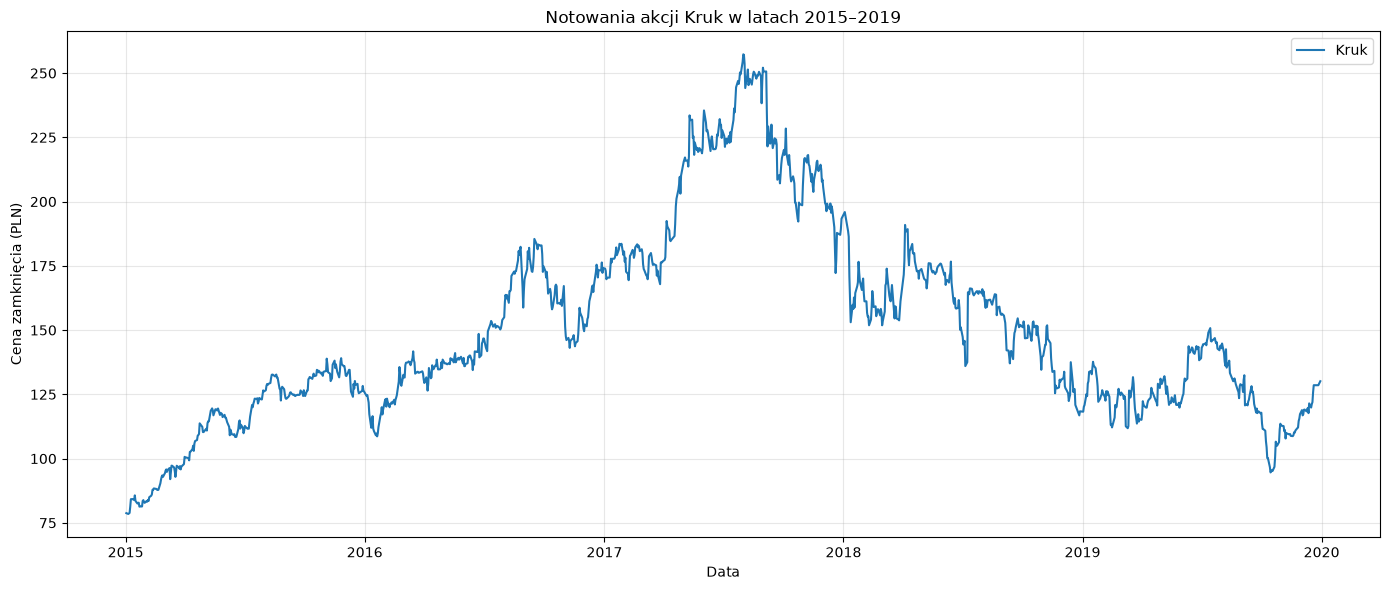

In [20]:
plt.figure(figsize=(14, 6))

plt.plot(KRU['Data'], KRU['Close_KRU'], label='Kruk')

plt.title('Notowania akcji Kruk w latach 2015–2019')
plt.xlabel('Data')
plt.ylabel('Cena zamknięcia (PLN)')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
KRU['Log_Return'] = np.log(KRU['Close_KRU'] / KRU['Close_KRU'].shift(1))

KRU

,Data,Close_KRU,Log_Return
0,2015-01-02,78.7747,NaN
1,2015-01-05,78.4558,-0.004056
2,2015-01-07,78.8523,0.005041
3,2015-01-08,81.3016,0.030589
4,2015-01-09,84.2107,0.035156
...,...,...,...
1242,2019-12-19,125.8400,0.031326
1243,2019-12-20,128.5570,0.021361
1244,2019-12-23,128.5570,0.000000
1245,2019-12-27,128.5570,0.000000


In [16]:
KRU['Close_KRU'].describe()

count    1247.000000
mean      150.418639
std        37.456812
min        78.455800
25%       124.290500
50%       141.607000
75%       172.657000
max       257.314000
Name: Close_KRU, dtype: float64

In [5]:
KRU['Log_Return'].describe()

count    1246.000000
mean        0.000403
std         0.021246
min        -0.099312
25%        -0.009841
50%         0.000290
75%         0.011428
max         0.180481
Name: Log_Return, dtype: float64

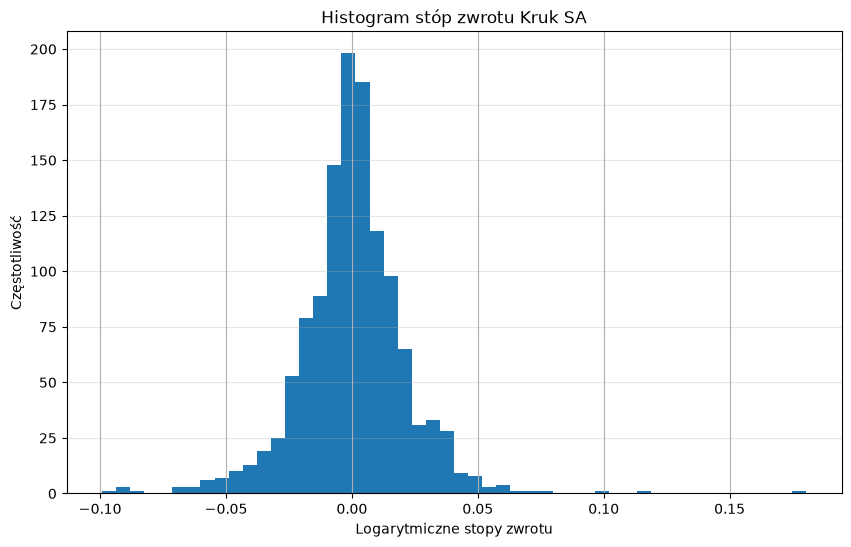

In [22]:
hist_KRU = KRU['Log_Return'].hist(bins=50, figsize=(10, 6))

plt.title('Histogram stóp zwrotu Kruk SA')
plt.xlabel('Logarytmiczne stopy zwrotu')
plt.ylabel('Częstotliwość')
plt.grid(axis='y', alpha=0.3)

plt.show()